In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [21]:
df1 = pd.read_excel("Concrete_Data.xls")

df1.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [22]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64  
 8   Concrete compressive strength(MPa, megapascals)  

In [23]:
df1.describe()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


In [24]:
df1.isnull().sum()

,0
Cement (component 1)(kg in a m^3 mixture),0
Blast Furnace Slag (component 2)(kg in a m^3 mixture),0
Fly Ash (component 3)(kg in a m^3 mixture),0
Water (component 4)(kg in a m^3 mixture),0
Superplasticizer (component 5)(kg in a m^3 mixture),0
Coarse Aggregate (component 6)(kg in a m^3 mixture),0
Fine Aggregate (component 7)(kg in a m^3 mixture),0
Age (day),0
"Concrete compressive strength(MPa, megapascals)",0


In [25]:
df1.duplicated().sum()

np.int64(25)

In [26]:
df1.dtypes

,0
Cement (component 1)(kg in a m^3 mixture),float64
Blast Furnace Slag (component 2)(kg in a m^3 mixture),float64
Fly Ash (component 3)(kg in a m^3 mixture),float64
Water (component 4)(kg in a m^3 mixture),float64
Superplasticizer (component 5)(kg in a m^3 mixture),float64
Coarse Aggregate (component 6)(kg in a m^3 mixture),float64
Fine Aggregate (component 7)(kg in a m^3 mixture),float64
Age (day),int64
"Concrete compressive strength(MPa, megapascals)",float64


In [27]:
df1 = df1.drop_duplicates()
df1 = df1.fillna(df1.median())

df1.isnull().sum()

,0
Cement (component 1)(kg in a m^3 mixture),0
Blast Furnace Slag (component 2)(kg in a m^3 mixture),0
Fly Ash (component 3)(kg in a m^3 mixture),0
Water (component 4)(kg in a m^3 mixture),0
Superplasticizer (component 5)(kg in a m^3 mixture),0
Coarse Aggregate (component 6)(kg in a m^3 mixture),0
Fine Aggregate (component 7)(kg in a m^3 mixture),0
Age (day),0
"Concrete compressive strength(MPa, megapascals)",0


In [28]:
df1.columns = [
    "Cement",
    "BlastFurnaceSlag",
    "FlyAsh",
    "Water",
    "Superplasticizer",
    "CoarseAggregate",
    "FineAggregate",
    "Age",
    "Strength"
]

df1.head()

,Cement,BlastFurnaceSlag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [29]:
X1 = df1.drop("Strength", axis=1)
y1 = df1["Strength"]
X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.2, random_state=42
)

In [30]:
model1 = LinearRegression()

model1.fit(X1_train, y1_train)

LinearRegression()

In [31]:
y1_pred = model1.predict(X1_test)

y1_pred[:10]

array([23.45680145, 16.70502445, 22.45826643, 37.40306335, 42.87777329,
       22.1588173 , 14.61138028, 44.52480377, 33.29249742, 50.12599604])

In [32]:
print("MAE:", mean_absolute_error(y1_test, y1_pred))
print("MSE:", mean_squared_error(y1_test, y1_pred))
print("RMSE:", np.sqrt(mean_squared_error(y1_test, y1_pred)))
print("R2 Score:", r2_score(y1_test, y1_pred))

MAE: 8.896027820458997
MSE: 125.265338276725
RMSE: 11.19219988548833
R2 Score: 0.580108901995383


In [33]:
results1 = pd.DataFrame({
    "Actual Strength": y1_test.values,
    "Predicted Strength": y1_pred
})

results1.head(10)

,Actual Strength,Predicted Strength
0,19.009543,23.456801
1,24.290929,16.705024
2,26.322815,22.458266
3,34.569637,37.403063
4,44.133359,42.877773
5,33.003837,22.158817
6,17.275511,14.611380
7,25.422359,44.524804
8,33.729166,33.292497
9,34.397958,50.125996


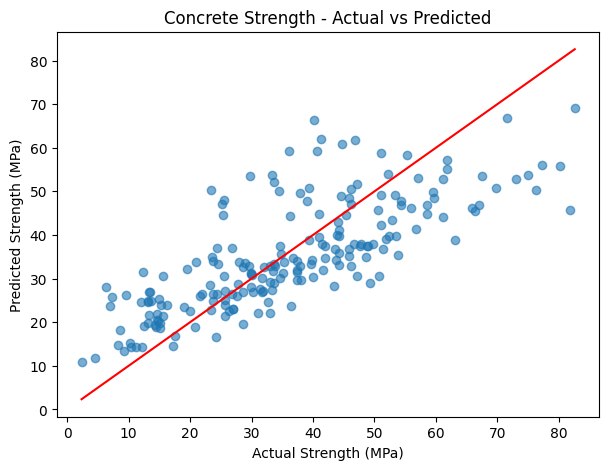

In [34]:
plt.figure(figsize=(7, 5))

plt.scatter(y1_test, y1_pred, alpha=0.6)

plt.plot(
    [y1_test.min(), y1_test.max()],
    [y1_test.min(), y1_test.max()],
    color="red"
)

plt.xlabel("Actual Strength (MPa)")
plt.ylabel("Predicted Strength (MPa)")
plt.title("Concrete Strength - Actual vs Predicted")
plt.show()

In [35]:
df2 = pd.read_excel("Folds5x2_pp.xlsx")

df2.head()

,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


In [36]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9568 entries, 0 to 9567
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AT      9568 non-null   float64
 1   V       9568 non-null   float64
 2   AP      9568 non-null   float64
 3   RH      9568 non-null   float64
 4   PE      9568 non-null   float64
dtypes: float64(5)
memory usage: 373.9 KB


In [37]:
df2.describe()

,AT,V,AP,RH,PE
count,9568.000000,9568.000000,9568.000000,9568.000000,9568.000000
mean,19.651231,54.305804,1013.259078,73.308978,454.365009
std,7.452473,12.707893,5.938784,14.600269,17.066995
min,1.810000,25.360000,992.890000,25.560000,420.260000
25%,13.510000,41.740000,1009.100000,63.327500,439.750000
50%,20.345000,52.080000,1012.940000,74.975000,451.550000
75%,25.720000,66.540000,1017.260000,84.830000,468.430000
max,37.110000,81.560000,1033.300000,100.160000,495.760000


In [38]:
df2.isnull().sum()

,0
AT,0
V,0
AP,0
RH,0
PE,0


In [39]:
df2.duplicated().sum()

np.int64(41)

In [40]:
df2.dtypes

,0
AT,float64
V,float64
AP,float64
RH,float64
PE,float64


In [41]:
df2.drop_duplicates(inplace=True)
df2.fillna(df2.median(), inplace=True)

df2.isnull().sum()

,0
AT,0
V,0
AP,0
RH,0
PE,0


In [42]:
features = ["AT", "V", "AP", "RH"]

X2 = df2[features]
y2 = df2["PE"]
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=21
)
model2 = LinearRegression()

model2.fit(X2_train, y2_train)

LinearRegression()

In [43]:
y2_pred = model2.predict(X2_test)

print("First 5 predicted power outputs:")
print(y2_pred[:5])

First 5 predicted power outputs:
[465.29179387 467.77171993 441.37220538 446.12036278 439.44210425]


In [44]:
mae = mean_absolute_error(y2_test, y2_pred)
mse = mean_squared_error(y2_test, y2_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y2_test, y2_pred)

print("POWER PLANT MODEL PERFORMANCE")
print("-" * 35)
print(f"Mean Absolute Error  : {mae:.3f} MW")
print(f"Mean Squared Error   : {mse:.3f} MW²")
print(f"Root Mean Square Error: {rmse:.3f} MW")
print(f"R-Squared Score      : {r2:.4f}")

POWER PLANT MODEL PERFORMANCE
-----------------------------------
Mean Absolute Error  : 3.631 MW
Mean Squared Error   : 20.096 MW²
Root Mean Square Error: 4.483 MW
R-Squared Score      : 0.9296


In [45]:
comparison = pd.DataFrame({
    "Actual Output (MW)": y2_test.values,
    "Estimated Output (MW)": y2_pred
})

comparison.head(10).round(2)

,Actual Output (MW),Estimated Output (MW)
0,467.81,465.29
1,466.71,467.77
2,437.53,441.37
3,446.31,446.12
4,432.89,439.44
5,462.54,464.90
6,462.30,463.68
7,483.83,481.88
8,438.66,439.69
9,440.97,446.99


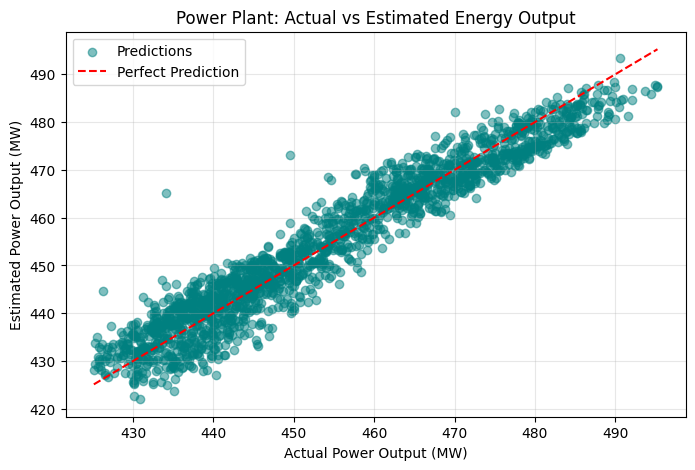

In [46]:
plt.figure(figsize=(8, 5))
plt.scatter(
    y2_test,
    y2_pred,
    color="teal",
    alpha=0.5,
    label="Predictions"
)
plt.plot(
    [y2_test.min(), y2_test.max()],
    [y2_test.min(), y2_test.max()],
    "r--",
    label="Perfect Prediction"
)
plt.title("Power Plant: Actual vs Estimated Energy Output")
plt.xlabel("Actual Power Output (MW)")
plt.ylabel("Estimated Power Output (MW)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [47]:
sample = pd.DataFrame({
    "AT": [20],
    "V": [45],
    "AP": [1015],
    "RH": [70]
})

prediction = model2.predict(sample)

print(f"Estimated Electrical Output: {prediction[0]:.2f} MW")

Estimated Electrical Output: 456.50 MW


In [48]:
!pip install gradio -q

In [49]:
import gradio as gr
def predict_concrete(cement, slag, flyash, water,
                     plasticizer, coarse, fine, age):

    data = pd.DataFrame([[
        cement, slag, flyash, water,
        plasticizer, coarse, fine, age
    ]], columns=X1.columns)

    prediction = model1.predict(data)[0]

    return f"{prediction:.2f} MPa"

In [50]:
def predict_power(temperature, vacuum, pressure, humidity):

    data = pd.DataFrame([[
        temperature, vacuum, pressure, humidity
    ]], columns=X2.columns)

    prediction = model2.predict(data)[0]

    return f"{prediction:.2f} MW"

In [51]:
with gr.Blocks(
    title="Engineering Prediction Dashboard",
    theme=gr.themes.Soft(primary_hue="cyan", neutral_hue="slate")
) as demo:
    gr.Markdown("""
    # ⚙️ Engineering Prediction Dashboard
    ### Linear Regression | ANN Laboratory Project

    Estimate concrete compressive strength and electrical
    power generation using machine learning.
    """)
    with gr.Tab("🏗️ Concrete Strength"):
        gr.Markdown("### Concrete Mix Analyzer")
        gr.Markdown("Adjust the concrete ingredients to estimate strength.")
        with gr.Row():
            with gr.Column():
                cement = gr.Slider(
                    100, 600, value=300,
                    label="Cement (kg/m³)"
                )
                slag = gr.Slider(
                    0, 400, value=100,
                    label="Blast Furnace Slag (kg/m³)"
                )
                flyash = gr.Slider(
                    0, 250, value=50,
                    label="Fly Ash (kg/m³)"
                )
                water = gr.Slider(
                    100, 250, value=180,
                    label="Water (kg/m³)"
                )
            with gr.Column():
                plasticizer = gr.Slider(
                    0, 35, value=5,
                    label="Superplasticizer (kg/m³)"
                )
                coarse = gr.Slider(
                    750, 1200, value=950,
                    label="Coarse Aggregate (kg/m³)"
                )
                fine = gr.Slider(
                    550, 1000, value=750,
                    label="Fine Aggregate (kg/m³)"
                )
                age = gr.Slider(
                    1, 365, value=28,
                    label="Concrete Age (Days)"
                )
        concrete_btn = gr.Button(
            "Analyze Concrete Strength",
            variant="primary"
        )
        concrete_result = gr.Textbox(
            label="Estimated Compressive Strength",
            interactive=False
        )
        concrete_btn.click(
            fn=predict_concrete,
            inputs=[
                cement, slag, flyash, water,
                plasticizer, coarse, fine, age
            ],
            outputs=concrete_result
        )
    with gr.Tab("⚡ Power Generation"):
        gr.Markdown("### Power Plant Performance Estimator")
        with gr.Row():
            with gr.Column():
                temperature = gr.Slider(
                    1, 38, value=20,
                    label="Ambient Temperature (°C)"
                )
                vacuum = gr.Slider(
                    25, 82, value=45,
                    label="Exhaust Vacuum (cm Hg)"
                )
            with gr.Column():
                pressure = gr.Slider(
                    990, 1035, value=1015,
                    label="Ambient Pressure (mbar)"
                )
                humidity = gr.Slider(
                    25, 100, value=70,
                    label="Relative Humidity (%)"
                )
        power_btn = gr.Button(
            "Estimate Power Output",
            variant="primary"
        )
        power_result = gr.Textbox(
            label="Estimated Electrical Output",
            interactive=False
        )
        power_btn.click(
            fn=predict_power,
            inputs=[
                temperature, vacuum,
                pressure, humidity
            ],
            outputs=power_result
        )
    gr.Markdown(
        "---\nEngineering Prediction System | Linear Regression"
    )
demo.launch(share=True)

/tmp/ipykernel_1480/3726357638.py:1: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://523b989ba7e4732d19.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [52]:
!pip install flask pyngrok -q


In [53]:
from flask import Flask, request, render_template_string
from pyngrok import ngrok
from threading import Thread
app = Flask(__name__)

html = """
<!DOCTYPE html>
<html>
<head>
    <title>Engineering ML Studio</title>

    <style>
        * {
            box-sizing: border-box;
        }

        body {
            margin: 0;
            font-family: Arial, sans-serif;
            background: #f3f6fb;
            color: #243247;
        }

        .sidebar {
            width: 240px;
            height: 100vh;
            background: #17243a;
            color: white;
            position: fixed;
            padding: 30px 20px;
        }

        .sidebar h2 {
            color: #62d6c9;
            margin-bottom: 40px;
        }

        .sidebar a {
            display: block;
            color: #dbe5f0;
            text-decoration: none;
            padding: 14px;
            margin-bottom: 12px;
            border-radius: 8px;
        }
        .sidebar a:hover {
            background: #30435f;
        }
        .main {
            margin-left: 240px;
            padding: 40px;
        }
        .card {
            background: white;
            padding: 30px;
            border-radius: 16px;
            max-width: 900px;
            box-shadow: 0 5px 25px #dce3ec;
        }
        .grid {
            display: grid;
            grid-template-columns: 1fr 1fr;
            gap: 20px;
        }
        label {
            font-weight: bold;
            font-size: 14px;
        }
        input {
            width: 100%;
            padding: 12px;
            margin-top: 8px;
            border: 1px solid #ccd6e0;
            border-radius: 8px;
        }
        button {
            background: #0d9488;
            color: white;
            border: none;
            padding: 14px 24px;
            border-radius: 8px;
            margin-top: 25px;
            cursor: pointer;
            font-weight: bold;
        }
        .result {
            margin-top: 25px;
            padding: 20px;
            background: #e0f7f3;
            border-left: 5px solid #0d9488;
            border-radius: 8px;
            font-size: 20px;
        }
        @media (max-width: 750px) {
            .sidebar {
                position: static;
                width: 100%;
                height: auto;
                padding: 15px;
            }
            .sidebar h2 {
                margin-bottom: 15px;
            }
            .main {
                margin-left: 0;
                padding: 20px;
            }
            .grid {
                grid-template-columns: 1fr;
            }
        }
    </style>
</head>
<body>
<div class="sidebar">
    <h2>⚙️ ML Studio</h2>
    <a href="/?page=concrete">🏗️ Concrete Analyzer</a>
    <a href="/?page=power">⚡ Power Plant</a>
</div>
<div class="main">
    <h1>Engineering Prediction Studio</h1>
    <p>Machine Learning Powered Estimation System</p>
    <div class="card">
        {% if page == "concrete" %}
        <h2>Concrete Strength Prediction</h2>
        <p>Enter concrete mixture details below.</p>
        <form method="POST">
            <input type="hidden" name="model" value="concrete">
            <div class="grid">
                <div>
                    <label>Cement (kg/m³)</label>
                    <input type="number" step="any"
                           name="cement" value="300" required>
                </div>
                <div>
                    <label>Blast Furnace Slag</label>
                    <input type="number" step="any"
                           name="slag" value="100" required>
                </div>
                <div>
                    <label>Fly Ash</label>
                    <input type="number" step="any"
                           name="flyash" value="50" required>
                </div>
                <div>
                    <label>Water</label>
                    <input type="number" step="any"
                           name="water" value="180" required>
                </div>
                <div>
                    <label>Superplasticizer</label>
                    <input type="number" step="any"
                           name="plasticizer" value="5" required>
                </div>
                <div>
                    <label>Coarse Aggregate</label>
                    <input type="number" step="any"
                           name="coarse" value="950" required>
                </div>
                <div>
                    <label>Fine Aggregate</label>
                    <input type="number" step="any"
                           name="fine" value="750" required>
                </div>
                <div>
                    <label>Concrete Age (Days)</label>
                    <input type="number" step="any"
                           name="age" value="28" required>
                </div>
            </div>
            <button type="submit">Calculate Strength</button>
        </form>
        {% elif page == "power" %}
        <h2>Power Plant Output Prediction</h2>
        <p>Enter environmental operating conditions.</p>
        <form method="POST">
            <input type="hidden" name="model" value="power">
            <div class="grid">
                <div>
                    <label>Ambient Temperature (°C)</label>
                    <input type="number" step="any"
                           name="temperature" value="20" required>
                </div>
                <div>
                    <label>Exhaust Vacuum (cm Hg)</label>
                    <input type="number" step="any"
                           name="vacuum" value="45" required>
                </div>
                <div>
                    <label>Ambient Pressure (mbar)</label>
                    <input type="number" step="any"
                           name="pressure" value="1015" required>
                </div>
                <div>
                    <label>Relative Humidity (%)</label>
                    <input type="number" step="any"
                           name="humidity" value="70" required>
                </div>
            </div>
            <button type="submit">Estimate Power Output</button>
        </form>
        {% endif %}
        {% if result %}
        <div class="result">
            <strong>Prediction Result:</strong> {{ result }}
        </div>
        {% endif %}
    </div>
</div>
</body>
</html>
"""
@app.route("/", methods=["GET", "POST"])
def home():
    page = request.args.get("page", "concrete")
    result = None
    if request.method == "POST":
        model = request.form["model"]
        if model == "concrete":
            page = "concrete"
            result = predict_concrete(
                float(request.form["cement"]),
                float(request.form["slag"]),
                float(request.form["flyash"]),
                float(request.form["water"]),
                float(request.form["plasticizer"]),
                float(request.form["coarse"]),
                float(request.form["fine"]),
                float(request.form["age"])
            )
        elif model == "power":
            page = "power"
            result = predict_power(
                float(request.form["temperature"]),
                float(request.form["vacuum"]),
                float(request.form["pressure"]),
                float(request.form["humidity"])
            )
    return render_template_string(
        html,
        page=page,
        result=result
    )

In [54]:
def run_flask():
    app.run(port=5000, use_reloader=False)

Thread(target=run_flask, daemon=True).start()

In [57]:
from getpass import getpass
from pyngrok import ngrok

token = getpass("Enter ngrok authentication token: ")

ngrok.set_auth_token(token)

public_url = ngrok.connect(5000)

print("Flask Website:", public_url.public_url)

Enter ngrok authentication token: ··········
Flask Website: https://jingle-mug-habitant.ngrok-free.dev
